In [1]:
import warnings

warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import os

# --- 1. Configuration ---
print("--- ⚙️  PHASE 1: Preparing Data ---")
REAL_DATA_PATH = '../../../data/data_with_features.csv'
SYNTHETIC_DATA_PATH = '../../../data/syntheticData/synthetic_data_sarima_statsmodels.csv'
TARGET_COLUMN = 'cumulative_mite_count'
GROUP_COLUMN = 'treatment_id'
TRAIN_RATIO = 0.8
VALIDATION_RATIO = 0.1

# Create a directory to store our processed data
PROCESSED_DATA_DIR = 'processed_data'
os.makedirs(PROCESSED_DATA_DIR, exist_ok=True)


# --- 2. Feature Engineering Function ---
def create_features(df):
    df = df.copy()
    df['observation_date'] = pd.to_datetime(df['observation_date'])
    df = df.sort_values(by=[GROUP_COLUMN, 'observation_date'])
    df['dayofweek'] = df['observation_date'].dt.dayofweek
    df['month'] = df['observation_date'].dt.month
    df['weekofyear'] = df['observation_date'].dt.isocalendar().week.astype(int)
    df['lag_1'] = df.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(1)
    df['lag_3'] = df.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(3)
    df['lag_7'] = df.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(7)
    df['rolling_mean_7'] = df.groupby(GROUP_COLUMN)['lag_1'].rolling(window=7, min_periods=1).mean().reset_index(drop=True)
    df['rolling_std_7'] = df.groupby(GROUP_COLUMN)['lag_1'].rolling(window=7, min_periods=1).std().reset_index(drop=True)
    df = df.dropna()
    return df

# --- 3. Process, Split, and Augment Data ---
real_df = pd.read_csv(REAL_DATA_PATH)
real_featured_df = create_features(real_df)

synthetic_df = pd.read_csv(SYNTHETIC_DATA_PATH)
synthetic_df[GROUP_COLUMN] = synthetic_df[GROUP_COLUMN].astype(str) + '_synth'
synthetic_featured_df = create_features(synthetic_df)

train_real_list, val_real_list, test_real_list = [], [], []
for group_id, group_df in real_featured_df.groupby(GROUP_COLUMN):
    n_rows = len(group_df)
    train_end = int(n_rows * TRAIN_RATIO)
    val_end = int(n_rows * (TRAIN_RATIO + VALIDATION_RATIO))
    train_real_list.append(group_df.iloc[:train_end])
    val_real_list.append(group_df.iloc[train_end:val_end])
    test_real_list.append(group_df.iloc[val_end:])

train_real_df = pd.concat(train_real_list)
val_df = pd.concat(val_real_list)
test_df = pd.concat(test_real_list)

train_ids = train_real_df[GROUP_COLUMN].unique()
synthetic_train_ids = [str(tid) + '_synth' for tid in train_ids]
synthetic_train_df = synthetic_featured_df[synthetic_featured_df[GROUP_COLUMN].isin(synthetic_train_ids)]
augmented_df = pd.concat([train_real_df, synthetic_train_df], ignore_index=True)


# --- 4. Define Features, Scale, and Save ---
features_to_use = [
    'dayofweek', 'month', 'weekofyear', 'lag_1', 'lag_3', 'lag_7',
    'rolling_mean_7', 'rolling_std_7', 'initial_female_count', 'leaf_area_cm2',
    'population_density', 'initial_growth_potential'
]

# Separate features (X) and target (y)
X_train = augmented_df[features_to_use]
y_train = augmented_df[[TARGET_COLUMN, GROUP_COLUMN, 'days_since_introduction']]

X_val = val_df[features_to_use]
y_val = val_df[[TARGET_COLUMN, GROUP_COLUMN, 'days_since_introduction']]

X_test = test_df[features_to_use]
y_test = test_df[[TARGET_COLUMN, GROUP_COLUMN, 'days_since_introduction']]


# Scale feature data
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Convert scaled arrays back to DataFrames
X_train_scaled = pd.DataFrame(X_train_scaled, columns=features_to_use, index=X_train.index)
X_val_scaled = pd.DataFrame(X_val_scaled, columns=features_to_use, index=X_val.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=features_to_use, index=X_test.index)

# Combine scaled features and targets for easy loading later
train_processed = pd.concat([X_train_scaled, y_train], axis=1)
val_processed = pd.concat([X_val_scaled, y_val], axis=1)
test_processed = pd.concat([X_test_scaled, y_test], axis=1)


# Save the final processed files
train_processed.to_csv(os.path.join(PROCESSED_DATA_DIR, 'train.csv'), index=False)
val_processed.to_csv(os.path.join(PROCESSED_DATA_DIR, 'validation.csv'), index=False)
test_processed.to_csv(os.path.join(PROCESSED_DATA_DIR, 'test.csv'), index=False)

print(f"✅ Data preparation complete. Processed files saved in '{PROCESSED_DATA_DIR}' directory.")
print(f"   Train set shape:      {train_processed.shape}")
print(f"   Validation set shape: {val_processed.shape}")
print(f"   Test set shape:       {test_processed.shape}")

--- ⚙️  PHASE 1: Preparing Data ---
✅ Data preparation complete. Processed files saved in 'processed_data' directory.
   Train set shape:      (3750, 15)
   Validation set shape: (202, 15)
   Test set shape:       (305, 15)


In [3]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def forecast_trajectory(model, initial_features_scaled, num_days, scaler_y, lag_1_col_index, is_lstm=False):
    """
    Generates a multi-step forecast entirely in the scaled space.
    """
    forecast_scaled = []
    current_features_scaled = initial_features_scaled.copy().reshape(1, -1)
    
    for _ in range(num_days):
        if is_lstm:
            model_input = current_features_scaled.reshape((1, current_features_scaled.shape[1], 1))
        else:
            model_input = current_features_scaled
            
        next_prediction_scaled = model.predict(model_input)[0]
        if isinstance(next_prediction_scaled, np.ndarray):
            next_prediction_scaled = next_prediction_scaled[0]

        forecast_scaled.append(next_prediction_scaled)
        current_features_scaled[0, lag_1_col_index] = next_prediction_scaled
        
    final_forecast = scaler_y.inverse_transform(np.array(forecast_scaled).reshape(-1, 1))
    return final_forecast.flatten()


def evaluate_model_performance(model, X_val_scaled, y_val, val_df_unscaled, scaler_y, feature_columns, model_type='feature'):
    """
    Performs a full evaluation for both one-step and multi-step forecasts.
    """
    results = {}
    is_lstm = (model_type == 'lstm')
    
    # --- 1. One-Step-Ahead Forecast Evaluation ---
    if is_lstm:
        X_val_reshaped = X_val_scaled.reshape((X_val_scaled.shape[0], X_val_scaled.shape[1], 1))
        preds_scaled = model.predict(X_val_reshaped, verbose=0)
    else:
        preds_scaled = model.predict(X_val_scaled)
        
    one_step_preds = scaler_y.inverse_transform(preds_scaled.reshape(-1, 1))
    
    results['one_step_mae'] = mean_absolute_error(y_val, one_step_preds)
    results['one_step_mse'] = mean_squared_error(y_val, one_step_preds)
    results['one_step_rmse'] = np.sqrt(results['one_step_mse'])
    results['one_step_r2'] = r2_score(y_val, one_step_preds)

    # --- 2. Full Trajectory Forecast Evaluation ---
    all_predictions, all_true_values = [], []
    lag_1_col_index = feature_columns.tolist().index('lag_1')
    
    row_counter = 0
    for group_id in val_df_unscaled['treatment_id'].unique():
        group_df = val_df_unscaled[val_df_unscaled['treatment_id'] == group_id]
        num_days_to_forecast = len(group_df)
        
        initial_features_scaled = X_val_scaled[row_counter]
        forecast = forecast_trajectory(model, initial_features_scaled, num_days_to_forecast, scaler_y, lag_1_col_index, is_lstm)
        
        all_predictions.extend(forecast)
        all_true_values.extend(group_df['cumulative_mite_count'].values)
        row_counter += num_days_to_forecast

    results['trajectory_mae'] = mean_absolute_error(all_true_values, all_predictions)
    results['trajectory_mse'] = mean_squared_error(all_true_values, all_predictions)
    results['trajectory_rmse'] = np.sqrt(results['trajectory_mse'])
    results['trajectory_r2'] = r2_score(all_true_values, all_predictions)
    
    return results

In [4]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
import joblib
import os

# --- 1. Load Processed Data ---
print("--- 💾 Loading Processed Data ---")
PROCESSED_DATA_DIR = 'processed_data'
train_df = pd.read_csv(f'{PROCESSED_DATA_DIR}/train.csv')
val_df = pd.read_csv(f'{PROCESSED_DATA_DIR}/validation.csv')

features_to_use = [col for col in train_df.columns if col not in ['cumulative_mite_count', 'treatment_id', 'days_since_introduction']]
TARGET_COLUMN = 'cumulative_mite_count'

# Separate features and target
X_train = train_df[features_to_use]
y_train = train_df[[TARGET_COLUMN]]
X_val = val_df[features_to_use]
y_val = val_df[[TARGET_COLUMN]]

# Initialize and fit scalers for both features and target
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
y_train_scaled = scaler_y.fit_transform(y_train)
X_val_scaled = scaler_X.transform(X_val)

# Save the scalers so we can load them for other models
joblib.dump(scaler_X, os.path.join(PROCESSED_DATA_DIR, 'scaler_X.gz'))
joblib.dump(scaler_y, os.path.join(PROCESSED_DATA_DIR, 'scaler_y.gz'))
print("   Data loaded and scalers fitted and saved.")


# --- 2. Train the Linear Regression Model ---
print("\n--- 🏋️ Training Linear Regression Model ---")
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train_scaled) # Train on scaled X and scaled y
print("   Model trained successfully.")


# --- 3. Evaluate the Model ---
print("\n--- 📊 Evaluating Model Performance on Validation Set ---")
# Use our reusable function with the corrected arguments
lr_results = evaluate_model_performance(
    model=lr_model,
    X_val_scaled=X_val_scaled,
    y_val=y_val,
    val_df_unscaled=val_df,
    scaler_y=scaler_y,
    feature_columns=X_train.columns,
    model_type='feature'
)

# --- 4. Display Results ---
print("\n--- 🏆 Linear Regression Results (Corrected) ---")
print(f"   One-Step Forecast:")
print(f"     - MAE: {lr_results['one_step_mae']:.4f}")
print(f"     - MSE: {lr_results['one_step_mse']:.4f}")
print(f"     - RMSE: {lr_results['one_step_rmse']:.4f}")
print(f"     - R²: {lr_results['one_step_r2']:.4f}")
print(f"\n   Full Trajectory (15-Day) Forecast:")
print(f"     - MAE: {lr_results['trajectory_mae']:.4f}")
print(f"     - MSE: {lr_results['trajectory_mse']:.4f}")
print(f"     - RMSE: {lr_results['trajectory_rmse']:.4f}")
print(f"     - R²: {lr_results['trajectory_r2']:.4f}")
print("\n--- ✅ Evaluation Complete ---")

--- 💾 Loading Processed Data ---
   Data loaded and scalers fitted and saved.

--- 🏋️ Training Linear Regression Model ---
   Model trained successfully.

--- 📊 Evaluating Model Performance on Validation Set ---

--- 🏆 Linear Regression Results (Corrected) ---
   One-Step Forecast:
     - MAE: 2.3709
     - MSE: 11.0667
     - RMSE: 3.3267
     - R²: 0.9996

   Full Trajectory (15-Day) Forecast:
     - MAE: 2.6728
     - MSE: 13.8432
     - RMSE: 3.7206
     - R²: 0.9995

--- ✅ Evaluation Complete ---


✅ Final model is ready.
--- Generating 15-day forecast for initial conditions: ---
   Initial Female Count: 5
   Leaf Area (cm²): 10.0

--- Forecasted Cumulative Mite Count ---
    Day  Predicted_Count
0     1              0.0
1     2              0.0
2     3              0.0
3     4              0.0
4     5              0.0
5     6              0.0
6     7              0.0
7     8              0.0
8     9              0.0
9    10              0.0
10   11              0.0
11   12              0.0
12   13              0.0
13   14              0.0
14   15              0.0


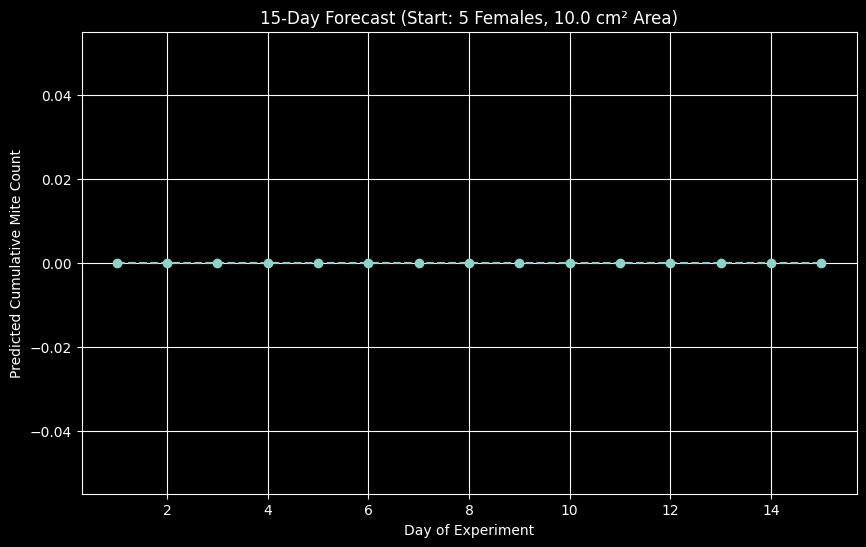

In [5]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import joblib
import os
import matplotlib.pyplot as plt

# --- 1. Define the CORRECTED Forecasting Logic ---

def forecast_trajectory(model, initial_features_scaled, num_days, scaler_y, feature_columns):
    """
    Generates a multi-step forecast entirely in the scaled space for stability.
    """
    # Get the integer index for the features we need to update
    lag_1_idx = feature_columns.tolist().index('lag_1')
    lag_3_idx = feature_columns.tolist().index('lag_3')
    lag_7_idx = feature_columns.tolist().index('lag_7')
    
    forecast_scaled = []
    current_features_scaled = initial_features_scaled.copy()

    for _ in range(num_days):
        # Predict the next scaled value (model expects 2D array)
        next_prediction_scaled = model.predict(current_features_scaled.reshape(1, -1))[0]
        
        # Ensure prediction is a single float and non-negative
        if isinstance(next_prediction_scaled, np.ndarray):
            next_prediction_scaled = next_prediction_scaled.item()
        next_prediction_scaled = max(0, next_prediction_scaled)
        
        forecast_scaled.append(next_prediction_scaled)
        
        # --- Update features FOR THE NEXT STEP entirely in the scaled space ---
        # Shift the lags
        current_features_scaled[lag_7_idx] = current_features_scaled[lag_3_idx]
        current_features_scaled[lag_3_idx] = current_features_scaled[lag_1_idx]
        current_features_scaled[lag_1_idx] = next_prediction_scaled
        
    # Inverse transform the entire list of scaled predictions at the very end
    final_forecast = scaler_y.inverse_transform(np.array(forecast_scaled).reshape(-1, 1))
    return final_forecast.flatten()


# --- 2. Create the Main Application Function ---

def predict_new_experiment(initial_females, leaf_area, model, scaler_X, scaler_y, num_days=15):
    """
    Generates a full 15-day forecast from only two initial inputs.
    """
    print(f"--- Generating 15-day forecast for initial conditions: ---")
    print(f"   Initial Female Count: {initial_females}")
    print(f"   Leaf Area (cm²): {leaf_area}")
    
    feature_columns = scaler_X.feature_names_in_
    initial_features = pd.DataFrame(np.zeros((1, len(feature_columns))), columns=feature_columns)
    
    # Populate the known and derived features
    initial_features['initial_female_count'] = initial_females
    initial_features['leaf_area_cm2'] = leaf_area
    if leaf_area > 0:
        initial_features['population_density'] = initial_females / leaf_area
    initial_features['initial_growth_potential'] = initial_females * leaf_area
    
    # Scale the initial feature set once
    initial_features_scaled = scaler_X.transform(initial_features)[0]
    
    # Run the stable autoregressive forecast
    predicted_counts = forecast_trajectory(model, initial_features_scaled, num_days, scaler_y, feature_columns)
    
    return predicted_counts

# --- 3. Example Usage ---
if __name__ == '__main__':
    PROCESSED_DATA_DIR = 'processed_data'
    
    # Load the trained model and scalers
    train_df = pd.read_csv(f'{PROCESSED_DATA_DIR}/train.csv')
    features_to_use = [col for col in train_df.columns if col not in ['cumulative_mite_count', 'treatment_id', 'days_since_introduction']]
    X_train = train_df[features_to_use]
    y_train = train_df[['cumulative_mite_count']]

    scaler_X_loaded = joblib.load(os.path.join(PROCESSED_DATA_DIR, 'scaler_X.gz'))
    scaler_y_loaded = joblib.load(os.path.join(PROCESSED_DATA_DIR, 'scaler_y.gz'))

    X_train_scaled = scaler_X_loaded.transform(X_train)
    y_train_scaled = scaler_y_loaded.transform(y_train)

    # Re-train the final model so it is ready to use
    final_model = LinearRegression()
    final_model.fit(X_train_scaled, y_train_scaled)
    print("✅ Final model is ready.")

    # --- MAKE A PREDICTION ---
    initial_female_input = 5
    leaf_area_input = 10.0

    forecast = predict_new_experiment(
        initial_females=initial_female_input,
        leaf_area=leaf_area_input,
        model=final_model,
        scaler_X=scaler_X_loaded,
        scaler_y=scaler_y_loaded,
        num_days=15
    )
    
    # --- Display the results ---
    print("\n--- Forecasted Cumulative Mite Count ---")
    day_by_day_forecast = pd.DataFrame({
        'Day': np.arange(1, 16),
        'Predicted_Count': forecast.round(2)
    })
    print(day_by_day_forecast)

    # Plot the forecast
    plt.figure(figsize=(10, 6))
    plt.plot(day_by_day_forecast['Day'], day_by_day_forecast['Predicted_Count'], marker='o', linestyle='--')
    plt.title(f'15-Day Forecast (Start: {initial_female_input} Females, {leaf_area_input} cm² Area)')
    plt.xlabel("Day of Experiment")
    plt.ylabel("Predicted Cumulative Mite Count")
    plt.grid(True)
    plt.show()

--- 💾 Loading Model and Scalers ---
✅ Final XGBoost model is ready.

--- Generating 15-day forecast for initial conditions: ---
   Initial Female Count: 500
   Leaf Area (cm²): 500

--- Forecasted Cumulative Mite Count ---
    Day  Predicted_Count
0     1                7
1     2              539
2     3              539
3     4              552
4     5              552
5     6              552
6     7              552
7     8              590
8     9              597
9    10              597
10   11              597
11   12              597
12   13              597
13   14              597
14   15              590


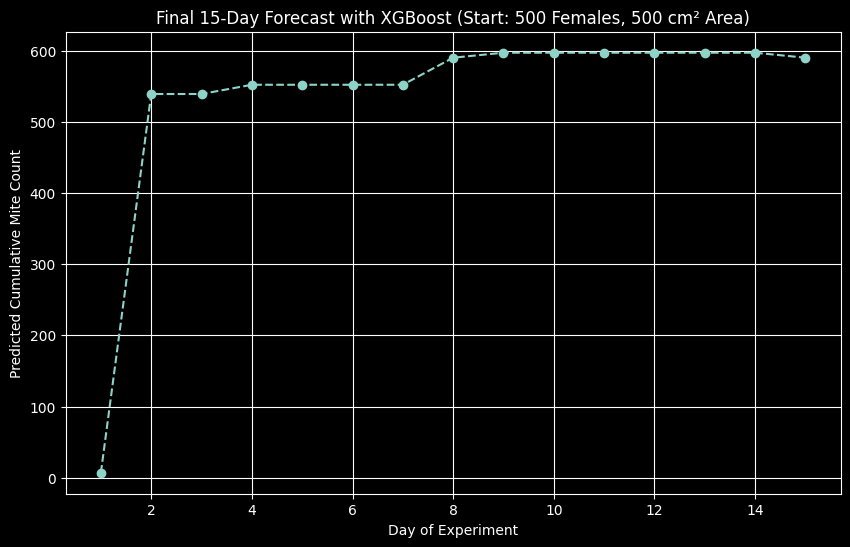

In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
import joblib
import os
import matplotlib.pyplot as plt
from datetime import timedelta

# --- 1. Load the Trained Model and Scalers ---
print("--- 💾 Loading Model and Scalers ---")
PROCESSED_DATA_DIR = 'processed_data'

# Load the scalers we saved during data preparation
scaler_X = joblib.load(os.path.join(PROCESSED_DATA_DIR, 'scaler_X.gz'))
scaler_y = joblib.load(os.path.join(PROCESSED_DATA_DIR, 'scaler_y.gz'))

# Load the processed training data to train the final model
train_df = pd.read_csv(f'{PROCESSED_DATA_DIR}/train.csv')
val_df = pd.read_csv(f'{PROCESSED_DATA_DIR}/validation.csv')
features_to_use = [col for col in train_df.columns if col not in ['cumulative_mite_count', 'treatment_id', 'days_since_introduction']]
X_train = train_df[features_to_use]
y_train = train_df[['cumulative_mite_count']]
X_val = val_df[features_to_use]
y_val = val_df[['cumulative_mite_count']]

X_train_scaled = scaler_X.transform(X_train)
y_train_scaled = scaler_y.transform(y_train)
X_val_scaled = scaler_X.transform(X_val)
y_val_scaled = scaler_y.transform(y_val)

# Train the final XGBoost model so it is ready to use
final_model = xgb.XGBRegressor(n_estimators=1000, learning_rate=0.05, eval_metric='rmse', early_stopping_rounds=50, n_jobs=-1)
final_model.fit(X_train_scaled, y_train_scaled, eval_set=[(X_val_scaled, y_val_scaled)], verbose=False)
print("✅ Final XGBoost model is ready.")


# --- 2. Define the Final, Corrected Forecasting Function ---

def predict_new_experiment(initial_females, leaf_area, model, scaler_X, scaler_y, num_days=15):
    """
    Generates a full 15-day forecast using a robust autoregressive loop that correctly updates all features.
    """
    print(f"\n--- Generating 15-day forecast for initial conditions: ---")
    print(f"   Initial Female Count: {initial_females}")
    print(f"   Leaf Area (cm²): {leaf_area}")

    feature_columns = scaler_X.feature_names_in_
    
    # This history will store the unscaled predictions to build future features
    history = [0] * 7 # Start with a buffer of 7 zeros for lag_7
    
    predictions = []
    start_date = pd.to_datetime('today')

    for day_num in range(1, num_days + 1):
        # --- Create the feature set for the current day ---
        current_features = pd.DataFrame(columns=feature_columns)
        
        # Populate initial conditions (static)
        current_features.loc[0, 'initial_female_count'] = initial_females
        current_features.loc[0, 'leaf_area_cm2'] = leaf_area
        if leaf_area > 0:
            current_features.loc[0, 'population_density'] = initial_females / leaf_area
        current_features.loc[0, 'initial_growth_potential'] = initial_females * leaf_area

        # Populate time features (dynamic)
        current_date = start_date + timedelta(days=day_num - 1)
        current_features.loc[0, 'dayofweek'] = current_date.dayofweek
        current_features.loc[0, 'month'] = current_date.month
        current_features.loc[0, 'weekofyear'] = current_date.isocalendar().week

        # Populate historical features from our growing history of predictions
        current_features.loc[0, 'lag_1'] = history[-1]
        current_features.loc[0, 'lag_3'] = history[-3]
        current_features.loc[0, 'lag_7'] = history[-7]
        
        # Correctly calculate rolling features from history
        rolling_hist = pd.Series(history)
        current_features.loc[0, 'rolling_mean_7'] = rolling_hist.iloc[-7:].mean()
        current_features.loc[0, 'rolling_std_7'] = rolling_hist.iloc[-7:].std()
        
        current_features = current_features.fillna(0) # Fill std=NaN at the start

        # --- Predict ---
        current_features_scaled = scaler_X.transform(current_features)
        prediction_scaled = model.predict(current_features_scaled)[0]
        
        # --- Inverse transform and store ---
        prediction_unscaled = scaler_y.inverse_transform(np.array(prediction_scaled).reshape(-1, 1))[0][0]
        prediction_unscaled = max(0, prediction_unscaled) # Enforce non-negativity
        
        predictions.append(prediction_unscaled)
        history.append(prediction_unscaled) # Update history for the next loop
        
    return np.array(predictions)


# --- 3. Run the Final Application ---
initial_female_input = 1
leaf_area_input = 10

forecast = predict_new_experiment(
    initial_females=initial_female_input,
    leaf_area=leaf_area_input,
    model=final_model,
    scaler_X=scaler_X_loaded,
    scaler_y=scaler_y_loaded,
    num_days=15
)

# --- 4. Display the Final Results ---
print("\n--- Forecasted Cumulative Mite Count ---")
day_by_day_forecast = pd.DataFrame({
    'Day': np.arange(1, 16),
    'Predicted_Count': forecast
})

# Round to the nearest whole number for a realistic count
day_by_day_forecast['Predicted_Count'] = day_by_day_forecast['Predicted_Count'].round(0).astype(int)
print(day_by_day_forecast)

# Plot the forecast
plt.figure(figsize=(10, 6))
plt.plot(day_by_day_forecast['Day'], day_by_day_forecast['Predicted_Count'], marker='o', linestyle='--')
plt.title(f'Final 15-Day Forecast with XGBoost (Start: {initial_female_input} Females, {leaf_area_input} cm² Area)')
plt.xlabel("Day of Experiment")
plt.ylabel("Predicted Cumulative Mite Count")
plt.grid(True)
plt.show()

In [7]:
import pandas as pd
import numpy as np
import xgboost as xgb
import joblib
import os

# --- 1. Load Processed Data and Scalers ---
print("--- 💾 Loading Processed Data ---")
PROCESSED_DATA_DIR = 'processed_data'
train_df = pd.read_csv(f'{PROCESSED_DATA_DIR}/train.csv')
val_df = pd.read_csv(f'{PROCESSED_DATA_DIR}/validation.csv')

features_to_use = [col for col in train_df.columns if col not in ['cumulative_mite_count', 'treatment_id', 'days_since_introduction']]
TARGET_COLUMN = 'cumulative_mite_count'

# Separate features and target
X_train = train_df[features_to_use]
y_train = train_df[[TARGET_COLUMN]]
X_val = val_df[features_to_use]
y_val = val_df[[TARGET_COLUMN]]

# Load the scalers that were saved during data prep
scaler_X = joblib.load(os.path.join(PROCESSED_DATA_DIR, 'scaler_X.gz'))
scaler_y = joblib.load(os.path.join(PROCESSED_DATA_DIR, 'scaler_y.gz'))

# Scale the data
X_train_scaled = scaler_X.transform(X_train)
y_train_scaled = scaler_y.transform(y_train)
X_val_scaled = scaler_X.transform(X_val)
print("   Data and scalers loaded.")


# --- 2. Train the XGBoost Model ---
print("\n--- 🏋️ Training XGBoost Model ---")
xgb_model = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    eval_metric='rmse',
    early_stopping_rounds=50,
    n_jobs=-1
)

# Fit the model on training data, using validation data for early stopping
xgb_model.fit(
    X_train_scaled, y_train_scaled,
    eval_set=[(X_val_scaled, scaler_y.transform(y_val))],
    verbose=False
)
print("   Model trained successfully.")


# --- 3. Evaluate the Model ---
print("\n--- 📊 Evaluating Model Performance on Validation Set ---")
xgb_results, xgb_preds_dict = evaluate_model_performance(
    model=xgb_model,
    X_val_scaled=X_val_scaled,
    y_val=y_val,
    val_df_unscaled=val_df,
    scaler_y=scaler_y,
    feature_columns=X_train.columns,
    model_type='feature'
)

# --- 4. Display Results and Plot ---
# CORRECTION 2: Changed title to XGBoost
print("\n--- 🏆 XGBoost Results ---")
print(f"   One-Step Forecast:")
# CORRECTION 3: Changed variable from lr_results to xgb_results
print(f"     - MAE: {xgb_results['one_step_mae']:.4f}, RMSE: {xgb_results['one_step_rmse']:.4f}, R²: {xgb_results['one_step_r2']:.4f}")
print(f"\n   Full Trajectory (15-Day) Forecast:")
print(f"     - MAE: {xgb_results['trajectory_mae']:.4f}, RMSE: {xgb_results['trajectory_rmse']:.4f}, R²: {xgb_results['trajectory_r2']:.4f}")


--- 💾 Loading Processed Data ---
   Data and scalers loaded.

--- 🏋️ Training XGBoost Model ---
   Model trained successfully.

--- 📊 Evaluating Model Performance on Validation Set ---


TypeError: forecast_trajectory() takes 5 positional arguments but 6 were given